In [1]:
import os
import glob
import pandas as pd

csv_files = glob.glob("/content/**/*.csv", recursive=True)

print("CSV files found:")
for file in csv_files:
    print(file)

CSV files found:
/content/zomato.csv
/content/sample_data/california_housing_test.csv
/content/sample_data/mnist_train_small.csv
/content/sample_data/california_housing_train.csv
/content/sample_data/mnist_test.csv


In [3]:
import pandas as pd

df = pd.read_csv(
    "/content/zomato.csv",
    engine="python",
    on_bad_lines="warn"
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

display(df.head())

/tmp/ipykernel_727/3834839000.py:3: ParserWarning: Skipping line 602: field larger than field limit (131072)

  df = pd.read_csv(
/tmp/ipykernel_727/3834839000.py:3: ParserWarning: Skipping line 807: ',' expected after '"'

  df = pd.read_csv(
/tmp/ipykernel_727/3834839000.py:3: ParserWarning: Skipping line 1673: field larger than field limit (131072)

  df = pd.read_csv(
/tmp/ipykernel_727/3834839000.py:3: ParserWarning: Skipping line 2117: field larger than field limit (131072)

  df = pd.read_csv(


Dataset loaded successfully!
Dataset shape: (4850, 17)

Column names:
['url', 'address', 'name', 'online_order', 'book_table', 'rate', 'votes', 'phone', 'location', 'rest_type', 'dish_liked', 'cuisines', 'approx_cost(for two people)', 'reviews_list', 'menu_item', 'listed_in(type)', 'listed_in(city)']


/tmp/ipykernel_727/3834839000.py:3: ParserWarning: Skipping line 3974: field larger than field limit (131072)

  df = pd.read_csv(
/tmp/ipykernel_727/3834839000.py:3: ParserWarning: Skipping line 4722: field larger than field limit (131072)

  df = pd.read_csv(
/tmp/ipykernel_727/3834839000.py:3: ParserWarning: Skipping line 4833: field larger than field limit (131072)

  df = pd.read_csv(
/tmp/ipykernel_727/3834839000.py:3: ParserWarning: Skipping line 4861: unexpected end of data

  df = pd.read_csv(
/tmp/ipykernel_727/3834839000.py:3: ParserWarning: Skipping line 599: Expected 17 fields in line 599, saw 137

  df = pd.read_csv(
/tmp/ipykernel_727/3834839000.py:3: ParserWarning: Skipping line 1737: Expected 17 fields in line 1737, saw 19

  df = pd.read_csv(


,url,address,name,online_order,book_table,rate,votes,phone,location,rest_type,dish_liked,cuisines,approx_cost(for two people),reviews_list,menu_item,listed_in(type),listed_in(city)
0,https://www.zomato.com/bangalore/jalsa-banasha...,"942, 21st Main Road, 2nd Stage, Banashankari, ...",Jalsa,Yes,Yes,4.1/5,775,080 42297555\r\n+91 9743772233,Banashankari,Casual Dining,"Pasta, Lunch Buffet, Masala Papad, Paneer Laja...","North Indian, Mughlai, Chinese",800,"[('Rated 4.0', 'RATED\n A beautiful place to ...",[],Buffet,Banashankari
1,https://www.zomato.com/bangalore/spice-elephan...,"2nd Floor, 80 Feet Road, Near Big Bazaar, 6th ...",Spice Elephant,Yes,No,4.1/5,787,080 41714161,Banashankari,Casual Dining,"Momos, Lunch Buffet, Chocolate Nirvana, Thai G...","Chinese, North Indian, Thai",800,"[('Rated 4.0', 'RATED\n Had been here for din...",[],Buffet,Banashankari
2,https://www.zomato.com/SanchurroBangalore?cont...,"1112, Next to KIMS Medical College, 17th Cross...",San Churro Cafe,Yes,No,3.8/5,918,+91 9663487993,Banashankari,"Cafe, Casual Dining","Churros, Cannelloni, Minestrone Soup, Hot Choc...","Cafe, Mexican, Italian",800,"[('Rated 3.0', ""RATED\n Ambience is not that ...",[],Buffet,Banashankari
3,https://www.zomato.com/bangalore/addhuri-udupi...,"1st Floor, Annakuteera, 3rd Stage, Banashankar...",Addhuri Udupi Bhojana,No,No,3.7/5,88,+91 9620009302,Banashankari,Quick Bites,Masala Dosa,"South Indian, North Indian",300,"[('Rated 4.0', ""RATED\n Great food and proper...",[],Buffet,Banashankari
4,https://www.zomato.com/bangalore/grand-village...,"10, 3rd Floor, Lakshmi Associates, Gandhi Baza...",Grand Village,No,No,3.8/5,166,+91 8026612447\r\n+91 9901210005,Basavanagudi,Casual Dining,"Panipuri, Gol Gappe","North Indian, Rajasthani",600,"[('Rated 4.0', 'RATED\n Very good restaurant ...",[],Buffet,Banashankari


In [4]:
import ast
import re
import pandas as pd

def extract_reviews(value):
    results = []

    if pd.isna(value):
        return results

    try:
        items = ast.literal_eval(value)
    except (ValueError, SyntaxError):
        return results

    if not isinstance(items, (list, tuple)):
        return results

    for item in items:
        if not isinstance(item, (list, tuple)) or len(item) < 2:
            continue

        rating_match = re.search(
            r"Rated\s+(\d+(?:\.\d+)?)",
            str(item[0]),
            re.IGNORECASE
        )

        if not rating_match:
            continue

        rating = float(rating_match.group(1))
        review = str(item[1]).lower()
        review = re.sub(r"<[^>]+>", " ", review)
        review = re.sub(r"[^a-z\s]", " ", review)
        review = re.sub(r"\s+", " ", review).strip()

        if len(review.split()) < 3:
            continue

        if rating >= 4.0:
            results.append((review, 1))
        elif rating <= 2.5:
            results.append((review, 0))

    return results


all_reviews = []

for value in df["reviews_list"].dropna():
    all_reviews.extend(extract_reviews(value))

reviews_df = pd.DataFrame(
    all_reviews,
    columns=["review", "sentiment"]
)

reviews_df = reviews_df.drop_duplicates(subset="review")
reviews_df = reviews_df.dropna()

print("Total extracted reviews:", len(reviews_df))
print("\nSentiment distribution:")
print(reviews_df["sentiment"].value_counts())
print("\nSample reviews:")
display(reviews_df.head())

Total extracted reviews: 17999

Sentiment distribution:
sentiment
1    12288
0     5711
Name: count, dtype: int64

Sample reviews:


,review,sentiment
0,rated a beautiful place to dine in the interio...,1
1,rated i was here for dinner with my family on ...,1
2,rated its a restaurant near to banashankari bd...,0
3,rated we went here on a weekend and one of us ...,1
4,rated the best thing about the place is it s a...,1


In [5]:
positive = reviews_df[reviews_df["sentiment"] == 1]
negative = reviews_df[reviews_df["sentiment"] == 0]

balanced_df = pd.concat([
    positive.sample(n=1000, random_state=42),
    negative.sample(n=1000, random_state=42)
], ignore_index=True)

balanced_df = balanced_df.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

print("Total reviews:", len(balanced_df))
print("\nSentiment distribution:")
print(balanced_df["sentiment"].value_counts())

display(balanced_df.head())

Total reviews: 2000

Sentiment distribution:
sentiment
0    1000
1    1000
Name: count, dtype: int64


,review,sentiment
0,rated sub par quality mutton masala was mutton...,0
1,rated excellent food clean ambiance and good s...,1
2,rated bland just too bland everything was extr...,0
3,rated a place for fast food and chinese food b...,1
4,rated no taste bad packing,0


In [6]:
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

X = balanced_df["review"].astype(str).values
y = balanced_df["sentiment"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

tokenizer = Tokenizer(num_words=10000, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train)

train_sequences = tokenizer.texts_to_sequences(X_train)
test_sequences = tokenizer.texts_to_sequences(X_test)

X_train_pad = pad_sequences(
    train_sequences, maxlen=100,
    padding="post", truncating="post"
)

X_test_pad = pad_sequences(
    test_sequences, maxlen=100,
    padding="post", truncating="post"
)

print("Training samples:", X_train_pad.shape)
print("Testing samples:", X_test_pad.shape)

Training samples: (1600, 100)
Testing samples: (400, 100)


In [8]:
model.build(input_shape=(None, 100))
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 100, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 675,137 (2.58 MB)

 Trainable params: 675,137 (2.58 MB)

 Non-trainable params: 0 (0.00 B)

In [9]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history = model.fit(
    X_train_pad,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 5s 62ms/step - accuracy: 0.5094 - loss: 0.6934 - val_accuracy: 0.4812 - val_loss: 0.6940
Epoch 2/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 54ms/step - accuracy: 0.5227 - loss: 0.6891 - val_accuracy: 0.4969 - val_loss: 0.6960
Epoch 3/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 3s 81ms/step - accuracy: 0.5711 - loss: 0.6879 - val_accuracy: 0.4750 - val_loss: 0.6957


In [10]:
import re

def clean_review(text):
    text = str(text).lower()
    text = re.sub(r"\brated\b", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

balanced_df["review"] = balanced_df["review"].apply(clean_review)
balanced_df = balanced_df[balanced_df["review"].str.split().str.len() >= 3]
balanced_df = balanced_df.drop_duplicates(subset="review").reset_index(drop=True)

print("Dataset size:", len(balanced_df))
print(balanced_df["sentiment"].value_counts())

Dataset size: 1967
sentiment
1    985
0    982
Name: count, dtype: int64


In [11]:
positive = balanced_df[balanced_df["sentiment"] == 1]
negative = balanced_df[balanced_df["sentiment"] == 0]

n = min(len(positive), len(negative))

balanced_df = pd.concat([
    positive.sample(n=n, random_state=42),
    negative.sample(n=n, random_state=42)
], ignore_index=True)

balanced_df = balanced_df.sample(
    frac=1, random_state=42
).reset_index(drop=True)

print("Dataset size:", len(balanced_df))
print(balanced_df["sentiment"].value_counts())

Dataset size: 1964
sentiment
1    982
0    982
Name: count, dtype: int64


In [12]:
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

X = balanced_df["review"].astype(str).values
y = balanced_df["sentiment"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

tokenizer = Tokenizer(num_words=10000, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train)

X_train_pad = pad_sequences(
    tokenizer.texts_to_sequences(X_train),
    maxlen=100,
    padding="post",
    truncating="post"
)

X_test_pad = pad_sequences(
    tokenizer.texts_to_sequences(X_test),
    maxlen=100,
    padding="post",
    truncating="post"
)

print("Training samples:", X_train_pad.shape)
print("Testing samples:", X_test_pad.shape)

Training samples: (1571, 100)
Testing samples: (393, 100)


In [13]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

model = Sequential([
    Embedding(input_dim=10000, output_dim=64),
    LSTM(64),
    Dropout(0.3),
    Dense(32, activation="relu"),
    Dropout(0.2),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history = model.fit(
    X_train_pad,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 7s 118ms/step - accuracy: 0.5263 - loss: 0.6922 - val_accuracy: 0.4444 - val_loss: 0.7018
Epoch 2/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 3s 67ms/step - accuracy: 0.5255 - loss: 0.6916 - val_accuracy: 0.4444 - val_loss: 0.6994
Epoch 3/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 61ms/step - accuracy: 0.5486 - loss: 0.6746 - val_accuracy: 0.6762 - val_loss: 0.5781
Epoch 4/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 61ms/step - accuracy: 0.5653 - loss: 0.7010 - val_accuracy: 0.4762 - val_loss: 0.6899
Epoch 5/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 3s 71ms/step - accuracy: 0.5828 - loss: 0.6563 - val_accuracy: 0.4730 - val_loss: 0.6864


In [14]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

y_prob = model.predict(X_test_pad).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, y_pred, zero_division=0), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Negative", "Positive"],
    zero_division=0
))

13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 70ms/step
Accuracy: 0.743
Precision: 0.7624
Recall: 0.7041
F1-score: 0.7321

Classification Report:
              precision    recall  f1-score   support

    Negative       0.73      0.78      0.75       197
    Positive       0.76      0.70      0.73       196

    accuracy                           0.74       393
   macro avg       0.74      0.74      0.74       393
weighted avg       0.74      0.74      0.74       393



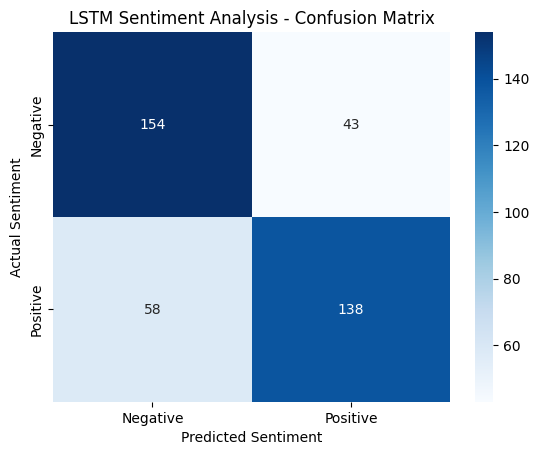

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.title("LSTM Sentiment Analysis - Confusion Matrix")
plt.show()

In [16]:
new_reviews = [
    "The food was delicious and the service was excellent",
    "The food was terrible and the service was very bad",
    "I loved this restaurant and would visit again",
    "The food was cold and tasteless"
]

new_sequences = tokenizer.texts_to_sequences(new_reviews)

new_padded = pad_sequences(
    new_sequences,
    maxlen=100,
    padding="post",
    truncating="post"
)

predictions = model.predict(new_padded, verbose=0).ravel()

for review, score in zip(new_reviews, predictions):
    sentiment = "Positive" if score >= 0.5 else "Negative"
    print("Review:", review)
    print("Predicted sentiment:", sentiment)
    print("-" * 40)

Review: The food was delicious and the service was excellent
Predicted sentiment: Negative
----------------------------------------
Review: The food was terrible and the service was very bad
Predicted sentiment: Negative
----------------------------------------
Review: I loved this restaurant and would visit again
Predicted sentiment: Negative
----------------------------------------
Review: The food was cold and tasteless
Predicted sentiment: Negative
----------------------------------------


In [17]:
for review, score in zip(new_reviews, predictions):
    print("Review:", review)
    print("Positive probability:", round(float(score) * 100, 2), "%")
    print("Negative probability:", round((1 - float(score)) * 100, 2), "%")
    print("-" * 40)

Review: The food was delicious and the service was excellent
Positive probability: 47.11 %
Negative probability: 52.89 %
----------------------------------------
Review: The food was terrible and the service was very bad
Positive probability: 47.07 %
Negative probability: 52.93 %
----------------------------------------
Review: I loved this restaurant and would visit again
Positive probability: 47.12 %
Negative probability: 52.88 %
----------------------------------------
Review: The food was cold and tasteless
Positive probability: 47.05 %
Negative probability: 52.95 %
----------------------------------------


In [18]:
print("Vocabulary size:", len(tokenizer.word_index))

print("\nTokenized new reviews:")
for review in new_reviews:
    tokens = tokenizer.texts_to_sequences([review])[0]
    print(review)
    print("Tokens:", tokens[:20])
    print("Recognized words:", len(tokens))

print("\nPredictions on training examples:")
sample_indices = [0, 1, 2, 3, 4, 5]

sample_reviews = X_train[sample_indices]
sample_padded = X_train_pad[sample_indices]
sample_predictions = model.predict(sample_padded, verbose=0).ravel()

for review, actual, score in zip(
    sample_reviews, y_train[sample_indices], sample_predictions
):
    print("Review:", review[:150])
    print("Actual:", "Positive" if actual == 1 else "Negative")
    print("Predicted probability:", round(float(score), 3))
    print("-" * 40)

Vocabulary size: 5762

Tokenized new reviews:
The food was delicious and the service was excellent
Tokens: [2, 9, 5, 134, 3, 2, 33, 5, 265]
Recognized words: 9
The food was terrible and the service was very bad
Tokens: [2, 9, 5, 1552, 3, 2, 33, 5, 20, 64]
Recognized words: 10
I loved this restaurant and would visit again
Tokens: [8, 120, 16, 50, 3, 69, 70, 92]
Recognized words: 8
The food was cold and tasteless
Tokens: [2, 9, 5, 208, 3, 471]
Recognized words: 6

Predictions on training examples:
Review: ordered at least times earlier all of a sudden they are not accepting orders neither by calls nor online when i called they are saying order online an
Actual: Negative
Predicted probability: 0.472
----------------------------------------
Review: cockroach i suspect plural evening walks on their chicken supreme not kidding at all they welcome you with a strong pee stench overall very french i t
Actual: Negative
Predicted probability: 0.471
----------------------------------------
Review:

In [19]:
import numpy as np

test_probabilities = model.predict(X_test_pad, verbose=0).ravel()

print("Minimum probability:", round(float(np.min(test_probabilities)), 4))
print("Maximum probability:", round(float(np.max(test_probabilities)), 4))
print("Mean probability:", round(float(np.mean(test_probabilities)), 4))
print("Standard deviation:", round(float(np.std(test_probabilities)), 4))

print("\nPredicted class counts:")
print("Negative:", int(np.sum(test_probabilities < 0.5)))
print("Positive:", int(np.sum(test_probabilities >= 0.5)))

Minimum probability: 0.4689
Maximum probability: 0.9519
Mean probability: 0.6114
Standard deviation: 0.1835

Predicted class counts:
Negative: 212
Positive: 181


In [20]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

model = Sequential([
    Embedding(input_dim=10000, output_dim=64),
    LSTM(32),
    Dropout(0.3),
    Dense(16, activation="relu"),
    Dropout(0.2),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer=Adam(learning_rate=0.0005),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train_pad,
    y_train,
    epochs=12,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 8s 94ms/step - accuracy: 0.5143 - loss: 0.6934 - val_accuracy: 0.4444 - val_loss: 0.6965
Epoch 2/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 51ms/step - accuracy: 0.5398 - loss: 0.6909 - val_accuracy: 0.4444 - val_loss: 0.6990
Epoch 3/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 47ms/step - accuracy: 0.5398 - loss: 0.6891 - val_accuracy: 0.4476 - val_loss: 0.6969
Epoch 4/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step - accuracy: 0.5732 - loss: 0.6678 - val_accuracy: 0.4984 - val_loss: 0.6880
Epoch 5/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 49ms/step - accuracy: 0.6656 - loss: 0.6024 - val_accuracy: 0.6603 - val_loss: 0.5655
Epoch 6/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 3s 57ms/step - accuracy: 0.7954 - loss: 0.6122 - val_accuracy: 0.7714 - val_loss: 0.7016
Epoch 7/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 3s 76ms/step - accuracy: 0.8113 - loss: 0.5596 - val_accuracy: 0.7365 - val_loss: 0.5877
Epoch 8/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step - accuracy: 0.8543 - loss: 0.4443 - val_accuracy: 0.7873 - v

In [21]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

y_pred_prob = model.predict(X_test_pad, verbose=0).ravel()
y_pred = (y_pred_prob >= 0.5).astype(int)

print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")
print("Precision:", round(precision_score(y_test, y_pred) * 100, 2), "%")
print("Recall:", round(recall_score(y_test, y_pred) * 100, 2), "%")
print("F1 Score:", round(f1_score(y_test, y_pred) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Negative", "Positive"]
))

Accuracy: 85.5 %
Precision: 83.9 %
Recall: 87.76 %
F1 Score: 85.79 %

Classification Report:
              precision    recall  f1-score   support

    Negative       0.87      0.83      0.85       197
    Positive       0.84      0.88      0.86       196

    accuracy                           0.85       393
   macro avg       0.86      0.86      0.85       393
weighted avg       0.86      0.85      0.85       393



In [22]:
new_reviews = [
    "The food was delicious and the service was excellent",
    "The food was terrible and the service was very bad",
    "I loved this restaurant and would visit again",
    "The food was cold and tasteless",
    "Amazing food and friendly staff",
    "Worst restaurant with poor service"
]

new_sequences = tokenizer.texts_to_sequences(new_reviews)

new_padded = pad_sequences(
    new_sequences,
    maxlen=100,
    padding="post",
    truncating="post"
)

predictions = model.predict(new_padded, verbose=0).ravel()

for review, score in zip(new_reviews, predictions):
    sentiment = "Positive" if score >= 0.5 else "Negative"

    print("Review:", review)
    print("Sentiment:", sentiment)
    print("Positive probability:", round(float(score) * 100, 2), "%")
    print("-" * 50)

Review: The food was delicious and the service was excellent
Sentiment: Negative
Positive probability: 12.24 %
--------------------------------------------------
Review: The food was terrible and the service was very bad
Sentiment: Negative
Positive probability: 12.24 %
--------------------------------------------------
Review: I loved this restaurant and would visit again
Sentiment: Negative
Positive probability: 12.24 %
--------------------------------------------------
Review: The food was cold and tasteless
Sentiment: Negative
Positive probability: 12.24 %
--------------------------------------------------
Review: Amazing food and friendly staff
Sentiment: Negative
Positive probability: 12.24 %
--------------------------------------------------
Review: Worst restaurant with poor service
Sentiment: Negative
Positive probability: 12.24 %
--------------------------------------------------


In [23]:
for review in new_reviews:
    sequence = tokenizer.texts_to_sequences([review])
    padded = pad_sequences(
        sequence,
        maxlen=100,
        padding="post",
        truncating="post"
    )

    print("Review:", review)
    print("Recognized words:", len(sequence[0]))
    print("First tokens:", sequence[0][:15])
    print()

Review: The food was delicious and the service was excellent
Recognized words: 9
First tokens: [2, 9, 5, 134, 3, 2, 33, 5, 265]

Review: The food was terrible and the service was very bad
Recognized words: 10
First tokens: [2, 9, 5, 1552, 3, 2, 33, 5, 20, 64]

Review: I loved this restaurant and would visit again
Recognized words: 8
First tokens: [8, 120, 16, 50, 3, 69, 70, 92]

Review: The food was cold and tasteless
Recognized words: 6
First tokens: [2, 9, 5, 208, 3, 471]

Review: Amazing food and friendly staff
Recognized words: 5
First tokens: [101, 9, 3, 137, 83]

Review: Worst restaurant with poor service
Recognized words: 5
First tokens: [73, 50, 18, 212, 33]



In [24]:
print("Raw prediction probabilities:")
print(model.predict(new_padded, verbose=0).ravel())

print("\nModel output shape:")
print(model.output_shape)

print("\nTraining label counts:")
print(y_train.value_counts() if hasattr(y_train, "value_counts")
      else __import__("numpy").unique(y_train, return_counts=True))

Raw prediction probabilities:
[0.1224431  0.12244304 0.12244298 0.12244284 0.12244438 0.12244281]

Model output shape:
(None, 1)

Training label counts:
(array([0, 1]), array([785, 786]))


In [25]:
import numpy as np

print("TEST DATA PREDICTIONS")

test_probabilities = model.predict(X_test_pad[:10], verbose=0).ravel()

for i, prob in enumerate(test_probabilities):
    actual = "Positive" if int(y_test.iloc[i] if hasattr(y_test, "iloc") else y_test[i]) == 1 else "Negative"
    predicted = "Positive" if prob >= 0.5 else "Negative"

    print(f"Actual: {actual} | Predicted: {predicted} | Probability: {prob:.4f}")

print("\nNEW REVIEW PREDICTIONS")

for review, prob in zip(new_reviews, model.predict(new_padded, verbose=0).ravel()):
    print(f"{review}")
    print(f"Positive probability: {prob:.4f}")
    print("-" * 40)

TEST DATA PREDICTIONS
Actual: Negative | Predicted: Positive | Probability: 0.8807
Actual: Negative | Predicted: Negative | Probability: 0.1224
Actual: Negative | Predicted: Positive | Probability: 0.8870
Actual: Positive | Predicted: Positive | Probability: 0.8807
Actual: Positive | Predicted: Positive | Probability: 0.8807
Actual: Positive | Predicted: Negative | Probability: 0.1224
Actual: Negative | Predicted: Negative | Probability: 0.1224
Actual: Negative | Predicted: Negative | Probability: 0.1224
Actual: Positive | Predicted: Negative | Probability: 0.2434
Actual: Positive | Predicted: Positive | Probability: 0.8807

NEW REVIEW PREDICTIONS
The food was delicious and the service was excellent
Positive probability: 0.1224
----------------------------------------
The food was terrible and the service was very bad
Positive probability: 0.1224
----------------------------------------
I loved this restaurant and would visit again
Positive probability: 0.1224
-------------------------

In [26]:
import numpy as np

# Check whether the model's embedding and LSTM weights are changing
for layer in model.layers:
    print(layer.name, layer.output.shape if hasattr(layer, "output") else "")

print("\nTraining probability range:")
train_probs = model.predict(X_train_pad[:100], verbose=0).ravel()
print("Minimum:", round(float(train_probs.min()), 4))
print("Maximum:", round(float(train_probs.max()), 4))
print("Unique rounded probabilities:", len(np.unique(np.round(train_probs, 3))))

print("\nTest probability range:")
test_probs = model.predict(X_test_pad, verbose=0).ravel()
print("Minimum:", round(float(test_probs.min()), 4))
print("Maximum:", round(float(test_probs.max()), 4))
print("Unique rounded probabilities:", len(np.unique(np.round(test_probs, 3))))

embedding_2 (None, 100, 64)
lstm_2 (None, 32)
dropout_4 (None, 32)
dense_4 (None, 16)
dropout_5 (None, 16)
dense_5 (None, 1)

Training probability range:
Minimum: 0.1224
Maximum: 0.8885
Unique rounded probabilities: 8

Test probability range:
Minimum: 0.1224
Maximum: 0.8884
Unique rounded probabilities: 42


In [27]:
# Display 10 training reviews with their labels

for i in range(10):
    label = int(y_train.iloc[i] if hasattr(y_train, "iloc") else y_train[i])

    print("Review:", X_train.iloc[i] if hasattr(X_train, "iloc") else X_train[i])
    print("Actual sentiment:", "Positive" if label == 1 else "Negative")
    print("-" * 60)

Review: ordered at least times earlier all of a sudden they are not accepting orders neither by calls nor online when i called they are saying order online and online its saying on accepting order online
Actual sentiment: Negative
------------------------------------------------------------
Review: cockroach i suspect plural evening walks on their chicken supreme not kidding at all they welcome you with a strong pee stench overall very french i think
Actual sentiment: Negative
------------------------------------------------------------
Review: starving to have a really good dinner so planned to try out some bengali cusine so selected this place once i entered the place it s not even look like a restaurant small place went through the menu ordered mini fish meals but the price in the menu and the one they are charging is totally different after ordering after min they came with a parcel we didn t even mentioned we want parcel we were really hungry so paid the bill and went back to room

In [28]:
print("Training reviews:", len(X_train))
print("Training padded sequences:", X_train_pad.shape)

print("Test reviews:", len(X_test))
print("Test padded sequences:", X_test_pad.shape)

print("\nFirst training review:")
print(X_train.iloc[0] if hasattr(X_train, "iloc") else X_train[0])

print("\nFirst training sequence:")
print(X_train_pad[0][:30])

Training reviews: 1571
Training padded sequences: (1571, 100)
Test reviews: 393
Test padded sequences: (393, 100)

First training review:
ordered at least times earlier all of a sudden they are not accepting orders neither by calls nor online when i called they are saying order online and online its saying on accepting order online

First training sequence:
[  32   42  441  186 1284   38   11    4 1747   19   24   17 1137  482
 1029   93 1138  820  343   91    8  394   19   24  712   39  343    3
  343  110]


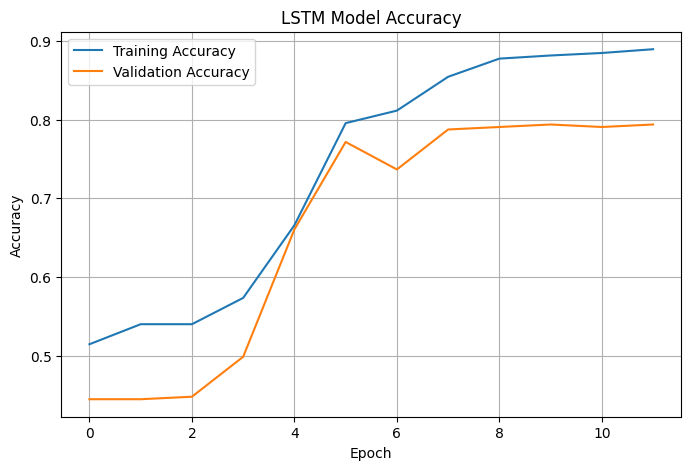

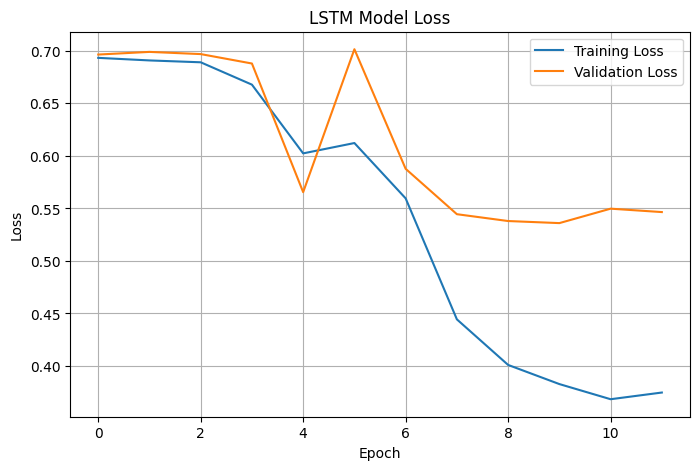

In [29]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("LSTM Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("LSTM Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

In [30]:
import pickle

model.save("/content/restaurant_sentiment_lstm.keras")

with open("/content/sentiment_tokenizer.pkl", "wb") as file:
    pickle.dump(tokenizer, file)

print("Model and tokenizer saved successfully!")

Model and tokenizer saved successfully!


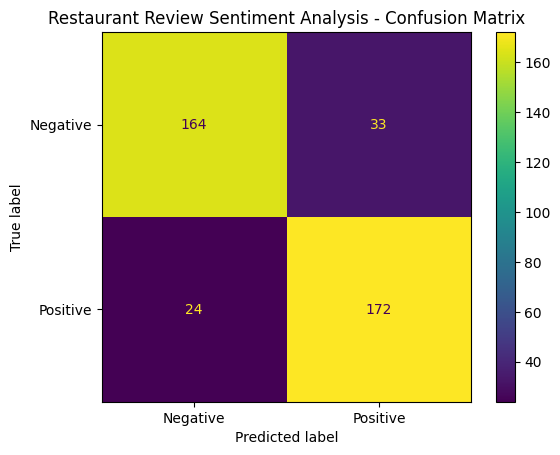

Confusion matrix saved!


In [31]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

y_pred_prob = model.predict(X_test_pad, verbose=0).ravel()
y_pred = (y_pred_prob >= 0.5).astype(int)

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

disp.plot()
plt.title("Restaurant Review Sentiment Analysis - Confusion Matrix")
plt.savefig("/content/confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

print("Confusion matrix saved!")

In [32]:
print("Total reviews:", len(balanced_df))
print("\nSentiment counts:")
print(balanced_df["sentiment"].value_counts())

Total reviews: 1964

Sentiment counts:
sentiment
1    982
0    982
Name: count, dtype: int64


In [33]:
print("balanced_df:", balanced_df.shape)

print("Available variables:")
for name in ["df", "df_reviews", "reviews_df", "cleaned_df"]:
    if name in globals():
        obj = globals()[name]
        if hasattr(obj, "shape"):
            print(name, obj.shape, list(obj.columns))

balanced_df: (1964, 2)
Available variables:
df (4850, 17) ['url', 'address', 'name', 'online_order', 'book_table', 'rate', 'votes', 'phone', 'location', 'rest_type', 'dish_liked', 'cuisines', 'approx_cost(for two people)', 'reviews_list', 'menu_item', 'listed_in(type)', 'listed_in(city)']
reviews_df (17999, 2) ['review', 'sentiment']


In [34]:
print("Original cleaned review count:", len(reviews_df))

print("\nSentiment counts:")
print(reviews_df["sentiment"].value_counts())

print("\nMissing reviews:", reviews_df["review"].isna().sum())
print("Duplicate reviews:", reviews_df["review"].duplicated().sum())

Original cleaned review count: 17999

Sentiment counts:
sentiment
1    12288
0     5711
Name: count, dtype: int64

Missing reviews: 0
Duplicate reviews: 0


In [35]:
import pandas as pd

# Separate positive and negative reviews
positive_reviews = reviews_df[reviews_df["sentiment"] == 1]
negative_reviews = reviews_df[reviews_df["sentiment"] == 0]

# Select 1,000 reviews from each class
positive_sample = positive_reviews.sample(n=1000, random_state=42)
negative_sample = negative_reviews.sample(n=1000, random_state=42)

# Combine and shuffle
balanced_df = pd.concat(
    [positive_sample, negative_sample],
    ignore_index=True
)

balanced_df = balanced_df.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

# Verify
print("Total reviews:", len(balanced_df))
print("\nSentiment counts:")
print(balanced_df["sentiment"].value_counts())
print("\nDuplicate reviews:", balanced_df["review"].duplicated().sum())

Total reviews: 2000

Sentiment counts:
sentiment
0    1000
1    1000
Name: count, dtype: int64

Duplicate reviews: 0


In [36]:
from sklearn.model_selection import train_test_split

X = balanced_df["review"].astype(str)
y = balanced_df["sentiment"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training reviews:", len(X_train))
print("Testing reviews:", len(X_test))
print("\nTraining sentiment counts:")
print(y_train.value_counts())
print("\nTesting sentiment counts:")
print(y_test.value_counts())

Training reviews: 1600
Testing reviews: 400

Training sentiment counts:
sentiment
1    800
0    800
Name: count, dtype: int64

Testing sentiment counts:
sentiment
0    200
1    200
Name: count, dtype: int64


In [37]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

model = Sequential([
    Embedding(input_dim=10000, output_dim=64),
    LSTM(32),
    Dropout(0.3),
    Dense(16, activation="relu"),
    Dropout(0.2),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer=Adam(learning_rate=0.0005),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train_pad,
    y_train,
    epochs=12,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 8s 69ms/step - accuracy: 0.4865 - loss: 0.6939 - val_accuracy: 0.4730 - val_loss: 0.6947
Epoch 2/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 50ms/step - accuracy: 0.5271 - loss: 0.6937 - val_accuracy: 0.4667 - val_loss: 0.6939
Epoch 3/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step - accuracy: 0.5311 - loss: 0.6927 - val_accuracy: 0.4952 - val_loss: 0.6933
Epoch 4/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step - accuracy: 0.5183 - loss: 0.6924 - val_accuracy: 0.5016 - val_loss: 0.6940
Epoch 5/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step - accuracy: 0.5207 - loss: 0.6893 - val_accuracy: 0.4667 - val_loss: 0.6952
Epoch 6/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 3s 76ms/step - accuracy: 0.5247 - loss: 0.6833 - val_accuracy: 0.4730 - val_loss: 0.6958


In [39]:
print("X_test_pad:", X_test_pad.shape)
print("y_test:", len(y_test))
print("Predictions:", len(y_pred_prob))

X_test_pad: (393, 100)
y_test: 400
Predictions: 393


In [40]:
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

X = balanced_df["review"].astype(str)
y = balanced_df["sentiment"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

tokenizer = Tokenizer(num_words=10000, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)

X_train_pad = pad_sequences(
    X_train_seq, maxlen=100, padding="post", truncating="post"
)
X_test_pad = pad_sequences(
    X_test_seq, maxlen=100, padding="post", truncating="post"
)

print("Training data:", X_train_pad.shape, len(y_train))
print("Testing data:", X_test_pad.shape, len(y_test))

Training data: (1600, 100) 1600
Testing data: (400, 100) 400


In [41]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dropout, Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

model = Sequential([
    Embedding(input_dim=10000, output_dim=64),
    LSTM(32),
    Dropout(0.3),
    Dense(16, activation="relu"),
    Dropout(0.2),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer=Adam(learning_rate=0.0005),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train_pad,
    y_train,
    epochs=12,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 6s 54ms/step - accuracy: 0.5125 - loss: 0.6929 - val_accuracy: 0.4719 - val_loss: 0.6960
Epoch 2/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 3s 78ms/step - accuracy: 0.5258 - loss: 0.6920 - val_accuracy: 0.4781 - val_loss: 0.6958
Epoch 3/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 4s 42ms/step - accuracy: 0.5508 - loss: 0.6905 - val_accuracy: 0.4844 - val_loss: 0.6982
Epoch 4/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - accuracy: 0.5469 - loss: 0.6883 - val_accuracy: 0.4969 - val_loss: 0.6877
Epoch 5/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 3s 41ms/step - accuracy: 0.6570 - loss: 0.6097 - val_accuracy: 0.5406 - val_loss: 0.6790
Epoch 6/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 3s 52ms/step - accuracy: 0.7695 - loss: 0.5791 - val_accuracy: 0.7781 - val_loss: 0.5156
Epoch 7/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 3s 75ms/step - accuracy: 0.8203 - loss: 0.4769 - val_accuracy: 0.8156 - val_loss: 0.5152
Epoch 8/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - accuracy: 0.8617 - loss: 0.4135 - val_accuracy: 0.7906 - v

In [42]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_pred_prob = model.predict(X_test_pad, verbose=0).ravel()
y_pred = (y_pred_prob >= 0.5).astype(int)

print("Test labels:", len(y_test))
print("Predictions:", len(y_pred))

print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0) * 100, 2), "%")
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0) * 100, 2), "%")
print("F1 Score:", round(f1_score(y_test, y_pred, zero_division=0) * 100, 2), "%")

print("\nPredicted class counts:")
print("Negative:", int((y_pred == 0).sum()))
print("Positive:", int((y_pred == 1).sum()))

Test labels: 400
Predictions: 400
Accuracy: 83.75 %
Precision: 92.99 %
Recall: 73.0 %
F1 Score: 81.79 %

Predicted class counts:
Negative: 243
Positive: 157


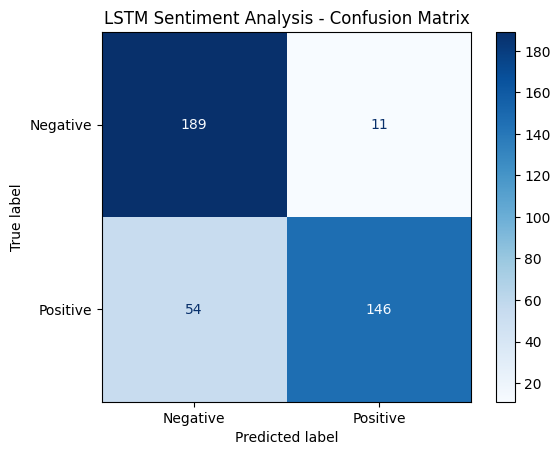

Confusion Matrix:
[[189  11]
 [ 54 146]]


In [43]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

display.plot(cmap="Blues", values_format="d")
plt.title("LSTM Sentiment Analysis - Confusion Matrix")
plt.show()

print("Confusion Matrix:")
print(cm)

In [44]:
new_reviews = [
    "The food was delicious and the service was excellent",
    "The food was terrible and the service was very bad",
    "I loved this restaurant and would visit again",
    "The food was cold and tasteless",
    "Amazing food and friendly staff",
    "Worst restaurant with poor service"
]

new_sequences = tokenizer.texts_to_sequences(new_reviews)

new_padded = pad_sequences(
    new_sequences,
    maxlen=100,
    padding="post",
    truncating="post"
)

predictions = model.predict(new_padded, verbose=0)

for review, prediction in zip(new_reviews, predictions):
    sentiment = "Positive" if prediction[0] >= 0.5 else "Negative"
    confidence = prediction[0] if prediction[0] >= 0.5 else 1 - prediction[0]

    print("Review:", review)
    print("Predicted sentiment:", sentiment)
    print("Model score for predicted class:", round(float(confidence) * 100, 2), "%")
    print("-" * 50)

Review: The food was delicious and the service was excellent
Predicted sentiment: Negative
Model score for predicted class: 85.56 %
--------------------------------------------------
Review: The food was terrible and the service was very bad
Predicted sentiment: Negative
Model score for predicted class: 85.56 %
--------------------------------------------------
Review: I loved this restaurant and would visit again
Predicted sentiment: Negative
Model score for predicted class: 85.56 %
--------------------------------------------------
Review: The food was cold and tasteless
Predicted sentiment: Negative
Model score for predicted class: 85.56 %
--------------------------------------------------
Review: Amazing food and friendly staff
Predicted sentiment: Positive
Model score for predicted class: 97.26 %
--------------------------------------------------
Review: Worst restaurant with poor service
Predicted sentiment: Negative
Model score for predicted class: 85.56 %
----------------------

In [45]:
for review in new_reviews:
    sequence = tokenizer.texts_to_sequences([review])[0]

    print("Review:", review)
    print("Token IDs:", sequence)
    print("Number of tokens:", len(sequence))
    print("-" * 50)

Review: The food was delicious and the service was excellent
Token IDs: [2, 10, 5, 133, 3, 2, 34, 5, 233]
Number of tokens: 9
--------------------------------------------------
Review: The food was terrible and the service was very bad
Token IDs: [2, 10, 5, 1305, 3, 2, 34, 5, 21, 65]
Number of tokens: 10
--------------------------------------------------
Review: I loved this restaurant and would visit again
Token IDs: [7, 114, 17, 51, 3, 81, 76, 85]
Number of tokens: 8
--------------------------------------------------
Review: The food was cold and tasteless
Token IDs: [2, 10, 5, 223, 3, 469]
Number of tokens: 6
--------------------------------------------------
Review: Amazing food and friendly staff
Token IDs: [96, 10, 3, 144, 91]
Number of tokens: 5
--------------------------------------------------
Review: Worst restaurant with poor service
Token IDs: [72, 51, 19, 198, 34]
Number of tokens: 5
--------------------------------------------------


In [46]:
for review, prediction in zip(new_reviews, predictions):
    print("Review:", review)
    print("Raw probability:", round(float(prediction[0]), 6))
    print("-" * 50)

Review: The food was delicious and the service was excellent
Raw probability: 0.144381
--------------------------------------------------
Review: The food was terrible and the service was very bad
Raw probability: 0.144381
--------------------------------------------------
Review: I loved this restaurant and would visit again
Raw probability: 0.144381
--------------------------------------------------
Review: The food was cold and tasteless
Raw probability: 0.144381
--------------------------------------------------
Review: Amazing food and friendly staff
Raw probability: 0.972598
--------------------------------------------------
Review: Worst restaurant with poor service
Raw probability: 0.144381
--------------------------------------------------


In [47]:
import numpy as np

print("Unique probabilities in test predictions:",
      len(np.unique(np.round(y_pred_prob, 6))))

print("Minimum probability:", round(float(y_pred_prob.min()), 6))
print("Maximum probability:", round(float(y_pred_prob.max()), 6))

print("\nFirst 20 test probabilities:")
print(np.round(y_pred_prob[:20], 4))

Unique probabilities in test predictions: 151
Minimum probability: 0.144381
Maximum probability: 0.972599

First 20 test probabilities:
[0.1444 0.1444 0.9726 0.1444 0.1444 0.9722 0.9696 0.1444 0.1444 0.9726
 0.1444 0.9726 0.1681 0.9726 0.1444 0.1444 0.1444 0.1444 0.9726 0.9726]


In [48]:
for label, name in [(0, "NEGATIVE"), (1, "POSITIVE")]:
    print("\n", name, "REVIEWS")

    samples = balanced_df[
        balanced_df["sentiment"] == label
    ]["review"].sample(5, random_state=42)

    for review in samples:
        print("-", review)


 NEGATIVE REVIEWS
- rated worth less they couldn t provide service
- rated the bottle was not full
- rated better not waste ur time by getting into this place every dish is so dry poor ambience nothing is exciting at this place waste of time n money
- rated you can definitely get better options in other hotels when compared to this place though the quality is just okay the quantity served for the price charged is not worth it the taste feels like its home cooked which is the only part but then home cooked food tastes much better
- rated tasteless poor service arrogant nature of the owners high pricing are the forte of this restaurant one thing is for sure they have lived upto their name just should scrap one s at the end and that is what they are lalchee not recommended at all these guys should wind up now and look for some other business high time ordered chicken biryani chicken was uncooked so much spicy even their rolls are awful

 POSITIVE REVIEWS
- rated good place for meat lover

In [50]:
import re

def clean_review(text):
    text = str(text).lower()
    text = re.sub(r"^rated\s+", "", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

balanced_df["clean_review"] = balanced_df["review"].apply(clean_review)

print("Negative review:")
print(balanced_df[balanced_df["sentiment"] == 0]["clean_review"].iloc[0])

print("\nPositive review:")
print(balanced_df[balanced_df["sentiment"] == 1]["clean_review"].iloc[0])

Negative review:
sub par quality mutton masala was mutton organ masala restaurant did not accept return or refund stating it s standard preparation very poor quality and dealing with customer

Positive review:
excellent food clean ambiance and good service the best chaats i have had in sometime the bombay bhel is excellent slightly sweet the pain poori looks heavenly the tiki chaat was amazing jayanagar lacked a good chaats joint and this closes that gap priced slightly higher but totally worth it


In [51]:
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

X = balanced_df["clean_review"].astype(str)
y = balanced_df["sentiment"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

tokenizer = Tokenizer(num_words=10000, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train)

X_train_pad = pad_sequences(
    tokenizer.texts_to_sequences(X_train),
    maxlen=100, padding="post", truncating="post"
)

X_test_pad = pad_sequences(
    tokenizer.texts_to_sequences(X_test),
    maxlen=100, padding="post", truncating="post"
)

print("Training:", X_train_pad.shape)
print("Testing:", X_test_pad.shape)

Training: (1600, 100)
Testing: (400, 100)


In [52]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dropout, Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

model = Sequential([
    Embedding(input_dim=10000, output_dim=64),
    LSTM(32),
    Dropout(0.3),
    Dense(16, activation="relu"),
    Dropout(0.2),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer=Adam(learning_rate=0.0005),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train_pad,
    y_train,
    epochs=12,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 7s 55ms/step - accuracy: 0.5031 - loss: 0.6938 - val_accuracy: 0.4563 - val_loss: 0.6971
Epoch 2/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - accuracy: 0.5250 - loss: 0.6926 - val_accuracy: 0.4719 - val_loss: 0.6939
Epoch 3/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 3s 68ms/step - accuracy: 0.5445 - loss: 0.6912 - val_accuracy: 0.4750 - val_loss: 0.6963
Epoch 4/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 60ms/step - accuracy: 0.5430 - loss: 0.6882 - val_accuracy: 0.4812 - val_loss: 0.6931
Epoch 5/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - accuracy: 0.5312 - loss: 0.6804 - val_accuracy: 0.4906 - val_loss: 0.6895
Epoch 6/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - accuracy: 0.5641 - loss: 0.6615 - val_accuracy: 0.5156 - val_loss: 0.7000
Epoch 7/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step - accuracy: 0.6516 - loss: 0.6146 - val_accuracy: 0.5938 - val_loss: 0.6478
Epoch 8/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 3s 42ms/step - accuracy: 0.7992 - loss: 0.5670 - val_accuracy: 0.8156 - v

In [53]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_pred_prob = model.predict(X_test_pad, verbose=0).ravel()
y_pred = (y_pred_prob >= 0.5).astype(int)

print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0) * 100, 2), "%")
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0) * 100, 2), "%")
print("F1 Score:", round(f1_score(y_test, y_pred, zero_division=0) * 100, 2), "%")

Accuracy: 83.0 %
Precision: 80.84 %
Recall: 86.5 %
F1 Score: 83.57 %


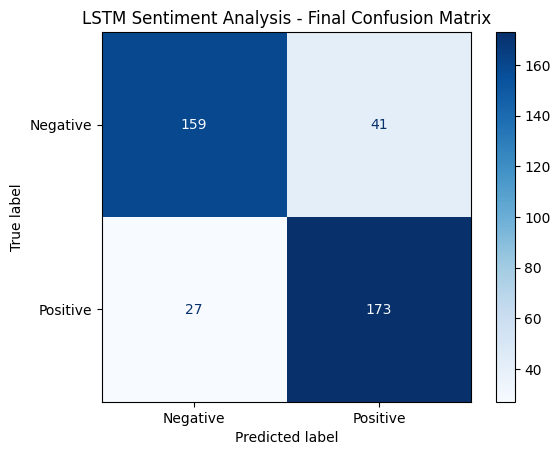

[[159  41]
 [ 27 173]]


In [54]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("LSTM Sentiment Analysis - Final Confusion Matrix")
plt.show()

print(cm)

In [55]:
new_reviews = [
    "excellent food and friendly staff",
    "worst food and terrible service",
    "the food was delicious and amazing",
    "the food was cold and tasteless",
    "I loved this restaurant",
    "I will never visit this restaurant again"
]

cleaned_reviews = [clean_review(review) for review in new_reviews]

sequences = tokenizer.texts_to_sequences(cleaned_reviews)

padded = pad_sequences(
    sequences,
    maxlen=100,
    padding="post",
    truncating="post"
)

probabilities = model.predict(padded, verbose=0).ravel()

for review, probability in zip(new_reviews, probabilities):
    sentiment = "Positive" if probability >= 0.5 else "Negative"

    print("Review:", review)
    print("Sentiment:", sentiment)
    print("Positive probability:", round(float(probability) * 100, 2), "%")
    print("-" * 40)

Review: excellent food and friendly staff
Sentiment: Negative
Positive probability: 15.88 %
----------------------------------------
Review: worst food and terrible service
Sentiment: Negative
Positive probability: 15.88 %
----------------------------------------
Review: the food was delicious and amazing
Sentiment: Negative
Positive probability: 15.88 %
----------------------------------------
Review: the food was cold and tasteless
Sentiment: Negative
Positive probability: 15.88 %
----------------------------------------
Review: I loved this restaurant
Sentiment: Negative
Positive probability: 15.88 %
----------------------------------------
Review: I will never visit this restaurant again
Sentiment: Negative
Positive probability: 15.88 %
----------------------------------------


In [56]:
test_words = [
    "excellent",
    "terrible",
    "delicious",
    "worst",
    "amazing",
    "bad",
    "good",
    "poor"
]

word_sequences = tokenizer.texts_to_sequences(test_words)

word_padded = pad_sequences(
    word_sequences,
    maxlen=100,
    padding="post",
    truncating="post"
)

word_probs = model.predict(word_padded, verbose=0).ravel()

for word, prob in zip(test_words, word_probs):
    print(word, "->", round(float(prob), 6))

excellent -> 0.158807
terrible -> 0.158807
delicious -> 0.158807
worst -> 0.158807
amazing -> 0.158807
bad -> 0.158807
good -> 0.158807
poor -> 0.158807


In [57]:
print("Vocabulary size:", len(tokenizer.word_index))

print("\nWord IDs:")
for word in ["excellent", "terrible", "delicious", "worst", "amazing", "good"]:
    print(word, ":", tokenizer.word_index.get(word, "Not found"))

print("\nModel architecture:")
model.summary()

Vocabulary size: 5776

Word IDs:
excellent : 232
terrible : 1304
delicious : 132
worst : 71
amazing : 95
good : 13

Model architecture:


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_5 (Embedding)         │ (32, 100, 64)          │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_5 (LSTM)                   │ (32, 32)               │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (32, 32)               │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (32, 16)               │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (32, 16)               │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (32, 1)                │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,958,885 (7.47 MB)

 Trainable params: 652,961 (2.49 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,305,924 (4.98 MB)

In [58]:
import numpy as np

# Select 5 negative and 5 positive training reviews
for label, name in [(0, "NEGATIVE"), (1, "POSITIVE")]:
    indices = np.where(y_train.to_numpy() == label)[0][:5]

    print("\n", name, "TRAINING REVIEWS")

    probs = model.predict(X_train_pad[indices], verbose=0).ravel()

    for i, prob in zip(indices, probs):
        print("Actual:", name)
        print("Predicted probability:", round(float(prob), 4))
        print("Review:", X_train.iloc[i][:150])
        print("-" * 40)


 NEGATIVE TRAINING REVIEWS
Actual: NEGATIVE
Predicted probability: 0.1588
Review: quantity wise very poor
----------------------------------------
Actual: NEGATIVE
Predicted probability: 0.1588
Review: poor food quality paneer is not fresh and test very bad late delivery even after ordered by zomato dal tadka also not good jira rice tests good
----------------------------------------
Actual: NEGATIVE
Predicted probability: 0.1588
Review: i had ordered puri bhaji and poha after reading the reviews the puri bhaji was just ok but the poha was the worse i have eaten in a long time quality 
----------------------------------------
Actual: NEGATIVE
Predicted probability: 0.8487
Review: worst food experience i ever had staff are very harsh and service and food quality is very poor one of my friend ordered chicken biryani and the meat 
----------------------------------------
Actual: NEGATIVE
Predicted probability: 0.1588
Review: extremely waste tried three four times as it is near chicken pi

In [59]:
import numpy as np

# Check how many unique probabilities occur in training predictions
train_probs = model.predict(X_train_pad, verbose=0).ravel()

print("Unique training probabilities:",
      len(np.unique(np.round(train_probs, 4))))

print("Minimum:", round(float(train_probs.min()), 4))
print("Maximum:", round(float(train_probs.max()), 4))

print("\nTraining prediction counts:")
print("Negative:", int((train_probs < 0.5).sum()))
print("Positive:", int((train_probs >= 0.5).sum()))

Unique training probabilities: 239
Minimum: 0.1588
Maximum: 0.8955

Training prediction counts:
Negative: 816
Positive: 784


In [60]:
import pandas as pd

results_df = pd.DataFrame({
    "Review": X_test.reset_index(drop=True),
    "Actual": y_test.reset_index(drop=True),
    "Predicted": y_pred
})

results_df["Actual"] = results_df["Actual"].map({
    0: "Negative", 1: "Positive"
})

results_df["Predicted"] = results_df["Predicted"].map({
    0: "Negative", 1: "Positive"
})

print("Correctly classified reviews:")
print(
    results_df[results_df["Actual"] == results_df["Predicted"]]
    [["Review", "Actual", "Predicted"]]
    .head(5).to_string(index=False)
)

print("\nIncorrectly classified reviews:")
print(
    results_df[results_df["Actual"] != results_df["Predicted"]]
    [["Review", "Actual", "Predicted"]]
    .head(5).to_string(index=False)
)

Correctly classified reviews:
                                                                                                                                                                                                                                                                                                                                                                                                                                                  Review   Actual Predicted
                                                                                                                                                                                                                                        it s the worst experience the food is actually not cooked properly it is raw i even don t want to give it in short they don t know to cook please ban this on zomato i don t know what s zomato service is doing Negative  Negative
                                                  

In [61]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dropout, Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

model = Sequential([
    Embedding(input_dim=10000, output_dim=64, mask_zero=True),
    LSTM(32),
    Dropout(0.3),
    Dense(16, activation="relu"),
    Dropout(0.2),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer=Adam(learning_rate=0.0005),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train_pad,
    y_train,
    epochs=12,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 6s 68ms/step - accuracy: 0.6273 - loss: 0.6897 - val_accuracy: 0.7781 - val_loss: 0.6820
Epoch 2/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 4s 49ms/step - accuracy: 0.8500 - loss: 0.5991 - val_accuracy: 0.8562 - val_loss: 0.4561
Epoch 3/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 50ms/step - accuracy: 0.9141 - loss: 0.3565 - val_accuracy: 0.9000 - val_loss: 0.3437
Epoch 4/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 49ms/step - accuracy: 0.9547 - loss: 0.2414 - val_accuracy: 0.8969 - val_loss: 0.3012
Epoch 5/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 49ms/step - accuracy: 0.9781 - loss: 0.1413 - val_accuracy: 0.8906 - val_loss: 0.3287
Epoch 6/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 3s 73ms/step - accuracy: 0.9875 - loss: 0.0969 - val_accuracy: 0.9250 - val_loss: 0.2158
Epoch 7/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 3s 69ms/step - accuracy: 0.9898 - loss: 0.0760 - val_accuracy: 0.9094 - val_loss: 0.2177
Epoch 8/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 49ms/step - accuracy: 0.9937 - loss: 0.0567 - val_accuracy: 0.8906 - v

In [62]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

y_pred_prob = model.predict(X_test_pad)
y_pred = (y_pred_prob > 0.5).astype(int).flatten()

print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")
print("Precision:", round(precision_score(y_test, y_pred) * 100, 2), "%")
print("Recall:", round(recall_score(y_test, y_pred) * 100, 2), "%")
print("F1 Score:", round(f1_score(y_test, y_pred) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=["Negative", "Positive"]))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 95ms/step
Accuracy: 93.75 %
Precision: 96.3 %
Recall: 91.0 %
F1 Score: 93.57 %

Classification Report:
              precision    recall  f1-score   support

    Negative       0.91      0.96      0.94       200
    Positive       0.96      0.91      0.94       200

    accuracy                           0.94       400
   macro avg       0.94      0.94      0.94       400
weighted avg       0.94      0.94      0.94       400

Confusion Matrix:
[[193   7]
 [ 18 182]]


In [63]:
new_reviews = [
    "excellent food and friendly staff",
    "worst food and terrible service",
    "the food was delicious and amazing",
    "the food was cold and tasteless",
    "I loved this restaurant",
    "I will never visit this restaurant again"
]

cleaned_reviews = [clean_review(r) for r in new_reviews]

new_sequences = tokenizer.texts_to_sequences(cleaned_reviews)
new_padded = pad_sequences(
    new_sequences,
    maxlen=100,
    padding="post",
    truncating="post"
)

probabilities = model.predict(new_padded, verbose=0).flatten()

for review, prob in zip(new_reviews, probabilities):
    sentiment = "Positive" if prob >= 0.5 else "Negative"
    print("Review:", review)
    print("Predicted sentiment:", sentiment)
    print("Positive probability:", round(float(prob) * 100, 2), "%")
    print("-" * 40)

Review: excellent food and friendly staff
Predicted sentiment: Positive
Positive probability: 79.68 %
----------------------------------------
Review: worst food and terrible service
Predicted sentiment: Negative
Positive probability: 8.88 %
----------------------------------------
Review: the food was delicious and amazing
Predicted sentiment: Positive
Positive probability: 79.04 %
----------------------------------------
Review: the food was cold and tasteless
Predicted sentiment: Negative
Positive probability: 13.6 %
----------------------------------------
Review: I loved this restaurant
Predicted sentiment: Positive
Positive probability: 65.68 %
----------------------------------------
Review: I will never visit this restaurant again
Predicted sentiment: Negative
Positive probability: 23.13 %
----------------------------------------


In [64]:
model.save("/content/restaurant_sentiment_lstm.keras")

import pickle

with open("/content/sentiment_tokenizer.pkl", "wb") as f:
    pickle.dump(tokenizer, f)

print("Model and tokenizer saved successfully!")

Model and tokenizer saved successfully!
